# 5. What the screen can and cannot resolve

A pooled screen's hit list is bounded by how many cells carry each perturbation.
This asks what effect size is detectable at a given cell count, and which
elements are too thinly covered for their absence from a hit list to mean
anything.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import methods as M
from methods import TABLES, lane_counts, mh_log_or, style
from methods import BLUE, ORANGE, RED, NEUTRAL, INK2

## Pick real hits across the effect-size range

**Purpose.** A subsampling curve built only on ACE2-sized effects says nothing
about the elements whose detection is marginal, so the eight elements used span
the whole range of significant effects.

In [2]:
DRAWS = 400

SUBSAMPLE_SIZES = [25, 40, 60, 80, 120, 160]

RNG = np.random.default_rng(0)

d = pd.read_csv(TABLES / "01_cell_state.tsv.gz", sep="\t")
d["gem_group"] = d.gem_group.astype(str)
lanes = sorted(d.gem_group.unique())
ntc = d[d.is_ntc]
c_l, d_l = lane_counts(ntc, lanes, "state")
p_l = np.divide(c_l, c_l + d_l, out=np.zeros(len(lanes)), where=(c_l + d_l) > 0)

# Pick real hits spanning the whole effect-size range, not just the biggest
# ones: a subsampling curve built only on ACE2-sized effects says nothing
# about the elements whose detection is actually marginal.
hits = pd.read_csv(TABLES / "03_hits_infection.tsv", sep="\t")
sig = hits[(~hits.is_ntc) & (hits.q_null < 0.1)].copy()
sig["abs_eff"] = sig.log_or_mh.abs()
sig = sig.sort_values("abs_eff")
picks = np.unique(np.linspace(0, len(sig) - 1, 8).round().astype(int))
strong = sig.iloc[picks]
print("elements used for the subsampling curve (weakest to strongest):")
print(strong[["target", "n_cells", "log_or_mh", "q_null"]].round(3).to_string(index=False))

elements used for the subsampling curve (weakest to strongest):
      target  n_cells  log_or_mh  q_null
    TMEM106B      380     -0.317   0.047
       SPNS1      177     -0.490   0.039
       SMAD3      107      0.538   0.045
      ARFRP1      155     -0.611   0.006
       SEC62       84      0.788   0.036
     TMPRSS2      184     -1.212   0.006
TMPRSS2+CTSL      205     -1.462   0.006
TMPRSS2+CTSB      174     -1.808   0.006


## Detection against cells retained

**Purpose.** Subsample each element's real cells down to 25-160 and re-run the
same test, to get a detection rate rather than a theoretical power curve.

**What it means.** The strong effects are detected almost always above about 60
cells, but the weaker real hits are detected less than half the time even at
the coverage the screen actually has. Hit lists from this design are
conservative: the misses are mostly power, not biology.

In [3]:
# ---------------------------------------- subsample real cells of real hits
rows = []
for _, h in strong.iterrows():
    sub = d[d.element == h.element]
    for k in SUBSAMPLE_SIZES + [len(sub)]:
        if k > len(sub):
            continue
        eff, hit = [], 0
        for _ in range(60):
            take = sub.sample(k, random_state=int(RNG.integers(1e9)))
            a_l, b_l = lane_counts(take, lanes, "state")
            lo, _se = mh_log_or(a_l, b_l, c_l, d_l)
            if not np.isfinite(lo):
                continue
            n_l = a_l + b_l
            a_null = RNG.binomial(np.repeat(n_l[None, :], DRAWS, axis=0), p_l[None, :])
            b_null = n_l[None, :] - a_null
            with np.errstate(divide="ignore", invalid="ignore"):
                null = np.log(
                    np.sum(a_null * d_l / (n_l + c_l + d_l), axis=1)
                    / np.sum(b_null * c_l / (n_l + c_l + d_l), axis=1)
                )
            p = (1 + np.sum(np.abs(null[np.isfinite(null)]) >= abs(lo))) / (DRAWS + 1)
            eff.append(lo)
            hit += int(p < 0.05)
        if eff:
            rows.append(
                dict(element=h.element, target=h.target, cells=k,
                     mean_log_or=float(np.mean(eff)),
                     sd_log_or=float(np.std(eff)),
                     detection_rate=hit / len(eff),
                     full_log_or=h.log_or_mh)
            )
curve = pd.DataFrame(rows)
curve.to_csv(TABLES / "05_downsample_curve.tsv", sep="\t", index=False)
print("\nsubsampling real hits: detection rate at p<0.05, by cells retained")
print(
    curve[curve.cells.isin(SUBSAMPLE_SIZES)]
    .pivot_table(index="cells", columns="target", values="detection_rate")
    .round(2).to_string()
)
print("\nand the effect estimate itself (mean log odds ratio):")
print(
    curve[curve.cells.isin(SUBSAMPLE_SIZES)]
    .pivot_table(index="cells", columns="target", values="mean_log_or")
    .round(2).to_string()
)


subsampling real hits: detection rate at p<0.05, by cells retained
target  ARFRP1  SEC62  SMAD3  SPNS1  TMEM106B  TMPRSS2  TMPRSS2+CTSB  TMPRSS2+CTSL
cells                                                                             
25        0.25   0.28   0.13   0.32      0.12     0.66          0.98          0.81
40        0.33   0.62   0.28   0.25      0.13     0.98          1.00          0.98
60        0.55   0.87   0.52   0.45      0.20     1.00          1.00          1.00
80        0.73   1.00   0.58   0.37      0.25     1.00          1.00          1.00
120       0.98    NaN    NaN   0.75      0.35     1.00          1.00          1.00
160        NaN    NaN    NaN   1.00      0.35     1.00          1.00          1.00

and the effect estimate itself (mean log odds ratio):
target  ARFRP1  SEC62  SMAD3  SPNS1  TMEM106B  TMPRSS2  TMPRSS2+CTSB  TMPRSS2+CTSL
cells                                                                             
25       -0.70   0.73   0.56  -0.61     -0.34  

## The smallest detectable effect

**Purpose.** The spread of the null at a given cell count sets the resolution
directly, independent of any particular element.

In [4]:
# -------------------------------- smallest detectable effect per cell count
# The null's spread at a given cell count sets the resolution of the screen.
rows = []
for k in [25, 40, 60, 80, 120, 160, 240]:
    n_l = np.full(len(lanes), k / len(lanes))
    n_l = np.floor(n_l).astype(int)
    n_l[: k - n_l.sum()] += 1
    a_null = RNG.binomial(np.repeat(n_l[None, :], 4000, axis=0), p_l[None, :])
    b_null = n_l[None, :] - a_null
    with np.errstate(divide="ignore", invalid="ignore"):
        null = np.log(
            np.sum(a_null * d_l / (n_l + c_l + d_l), axis=1)
            / np.sum(b_null * c_l / (n_l + c_l + d_l), axis=1)
        )
    null = null[np.isfinite(null)]
    rows.append(
        dict(cells=k,
             null_sd=float(np.std(null)),
             abs_log_or_at_p05=float(np.percentile(np.abs(null), 95)),
             fold_change_at_p05=float(np.exp(np.percentile(np.abs(null), 95)))))
det = pd.DataFrame(rows)
det.to_csv(TABLES / "05_detectable_effect.tsv", sep="\t", index=False)
print("\nresolution of the screen, from the NTC null alone:")
print(det.round(3).to_string(index=False))


resolution of the screen, from the NTC null alone:
 cells  null_sd  abs_log_or_at_p05  fold_change_at_p05
    25    0.456              0.885               2.424
    40    0.354              0.652               1.919
    60    0.273              0.545               1.725
    80    0.238              0.477               1.611
   120    0.194              0.390               1.476
   160    0.167              0.327               1.387
   240    0.137              0.273               1.313


## Which elements cannot be tested at all

**Purpose.** Apply each phenotype's coverage cut and list what falls out.

**What it means.** A sizeable minority of elements fail at least one cut, and
they are mostly essential genes, which drop out of the pool. For those,
absence from a hit list is informative about the perturbation's fitness cost,
not evidence of no effect on infection.

In [5]:
# ------------------------------------------------- underpowered elements
rep = pd.read_csv(TABLES / "02_element_representation.tsv", sep="\t")
rep["testable_infection"] = rep.n_cells >= 55
rep["testable_burden"] = rep.n_infected >= 20
rep["testable_isg"] = rep.n_bystander >= 30
under = rep[~(rep.testable_infection & rep.testable_burden & rep.testable_isg)]
under.to_csv(TABLES / "05_underpowered_elements.tsv", sep="\t", index=False)
print(
    f"\nelements of {len(rep)} not testable for at least one phenotype: {len(under)}"
    f"\n  infection (>=55 cells)      : {int((~rep.testable_infection).sum())} fail"
    f"\n  burden   (>=20 infected)    : {int((~rep.testable_burden).sum())} fail"
    f"\n  ISG      (>=30 bystanders)  : {int((~rep.testable_isg).sum())} fail"
)
print("\nthe 15 worst-represented elements (absence from a hit list means nothing here):")
print(
    under.nsmallest(15, "n_cells")[
        ["element", "target", "n_cells", "n_infected", "n_bystander"]
    ].to_string(index=False)
)


elements of 237 not testable for at least one phenotype: 73
  infection (>=55 cells)      : 47 fail
  burden   (>=20 infected)    : 67 fail
  ISG      (>=30 bystanders)  : 47 fail

the 15 worst-represented elements (absence from a hit list means nothing here):
                  element        target  n_cells  n_infected  n_bystander
        CRISPRi_039_COPB2         COPB2        1           0            1
       CRISPRi_093_POLR2B        POLR2B        1           1            0
         CRISPRi_061_GBF1          GBF1        4           2            0
      CRISPRi_012_ATP6V1A       ATP6V1A        5           0            2
         CRISPRi_150_YKT6          YKT6        5           2            3
        CRISPRi_119_SRP54         SRP54        6           3            3
CRISPRi_176_SREBF1_SREBF2 SREBF1+SREBF2        6           3            1
     CRISPRi_013_ATP6V1B2      ATP6V1B2        6           1            4
        CRISPRi_091_PCBP1         PCBP1        8           0            

## Figure: representation sets what the screen can find

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


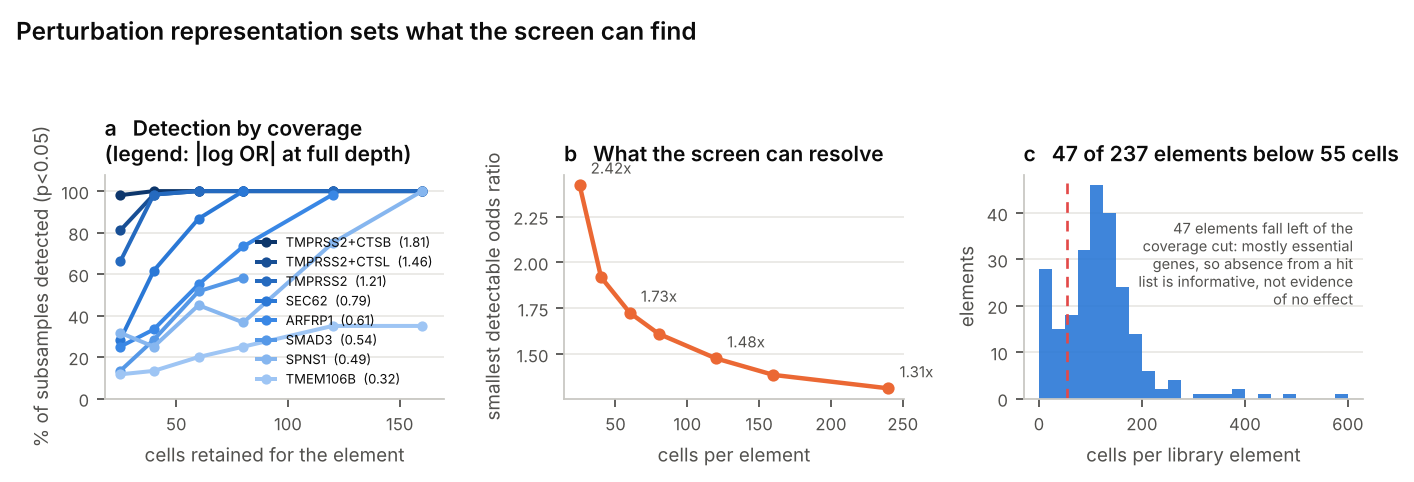

In [6]:
curve = M.table("05_downsample_curve.tsv")
det = M.table("05_detectable_effect.tsv")
rep = M.table("02_element_representation.tsv")

fig, axes = plt.subplots(1, 3, figsize=(8.6, 3.0))

ax = axes[0]
order = (curve.groupby("target").full_log_or.first().abs().sort_values(ascending=False))
ramp = ["#0d366b", "#184f95", "#256abf", "#2a78d6", "#3987e5", "#5598e7", "#86b6ef", "#9ec5f4"]
handles = []
for (tgt, _), col in zip(order.items(), ramp):
    s = curve[(curve.target == tgt) & curve.cells.isin([25, 40, 60, 80, 120, 160])]
    if len(s) < 2:
        continue
    s = s.sort_values("cells")
    ax.plot(s.cells, s.detection_rate * 100, color=col, marker="o", markersize=3.6,
            linewidth=1.8)
    handles.append(Line2D([], [], color=col, marker="o", markersize=3.6, linewidth=1.8,
                          label=f"{tgt}  ({abs(order[tgt]):.2f})"))
style(ax)
ax.set_xlabel("cells retained for the element")
ax.set_ylabel("% of subsamples detected (p<0.05)")
ax.set_xlim(18, 170)
ax.set_ylim(0, 108)
ax.legend(handles=handles, loc="lower right", fontsize=5.9, labelspacing=0.28,
          handlelength=1.4)
ax.set_title("a   Detection by coverage\n(legend: |log OR| at full depth)", loc="left")

ax = axes[1]
ax.plot(det.cells, det.fold_change_at_p05, color=ORANGE, marker="o", markersize=4.5)
style(ax)
ax.set_xlabel("cells per element")
ax.set_ylabel("smallest detectable odds ratio")
ax.set_title("b   What the screen can resolve", loc="left")
for _, r in det.iterrows():
    if r.cells in (25, 60, 120, 240):
        ax.annotate(f"{r.fold_change_at_p05:.2f}x", (r.cells, r.fold_change_at_p05),
                    textcoords="offset points", xytext=(5, 5), fontsize=6.8, color=INK2)

ax = axes[2]
v = rep.n_cells.clip(upper=600)
ax.hist(v, bins=np.arange(0, 620, 25), color=BLUE, linewidth=0, alpha=0.9)
ax.axvline(55, color=RED, linewidth=1.2, linestyle=(0, (4, 3)))
style(ax)
ax.set_xlabel("cells per library element")
ax.set_ylabel("elements")
n_under = int((rep.n_cells < 55).sum())
ax.set_title(f"c   {n_under} of {len(rep)} elements below 55 cells", loc="left")
ax.annotate(f"{n_under} elements fall left of the\ncoverage cut: mostly essential\ngenes, so absence from a hit\nlist is informative, not evidence\nof no effect",
            xy=(0.97, 0.80), xycoords="axes fraction", ha="right", va="top",
            fontsize=6.6, color=INK2)

fig.suptitle("Perturbation representation sets what the screen can find",
             x=0.005, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(M.FIGURES / "resolution.png")
plt.show()